In [1]:
import pacmap 
import numpy        as np
import pandas       as pd
import umap.umap_   as umap

from tqdm                               import tqdm
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
#from clustering.clusteringTimeSeries    import ClusteringTimeSeries
from clustering.plotClustering          import ClusteringResults

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

# scaler         = MinMaxScaler() 
# scaledCrusher1 = preData.normalizeData(data   = df, 
#                                        scaler = scaler)

In [3]:
df.drop_duplicates(subset='tiempo', inplace=True)
df_=df.copy()
df_.set_index('tiempo', inplace=True)
numeric_columns = df_.select_dtypes('number').columns
other_columns = df_.select_dtypes(include=['object','datetime64[ns]']).columns

aggregated_df = df_.resample('10min').agg({col: 'mean' for col in numeric_columns})
aggregated_df.loc[:,other_columns] = df.set_index('tiempo')[other_columns].resample('10min').ffill()
aggregated_df.reset_index(inplace=True)
aggregated_df.dropna(subset=numeric_columns, inplace=True)

In [4]:
scaler         = MinMaxScaler() 
scaledCrusher1 = preData.normalizeData(data   = aggregated_df, 
                                       scaler = scaler)

## Split time series graph

In [5]:
linePlot(data   = aggregated_df, 
         x      = 'tiempo', 
         y      = 'Piñón_ext(°C)', 
         color  = 'trajectory')

# Clustering

In [6]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 60, #150
                                        eps         = 2.5), #2.2

                       'pacmap': DBSCAN(min_samples = 60, #200
                                        eps         = 2.5)}  #4

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40),

                       'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:




In [7]:
Clusters = ClusteringResults(data                = aggregated_df, #preData.crusher1
                             dataNormalized      = dfManipulableVar, 
                             clusteringModels    = clusteringModels, 
                             dimReductionModels  = dimReductionModels)

In [8]:
# Train dimensinality reduction models wiht a trajectory
Clusters.trainPrevious(trainTrajectory='15')

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [9]:
# Clusters are calculated in embedding space for each trajectory
for trajectory in tqdm(Clusters.trajectories):
    Clusters.getResults(trajectory)

100%|██████████| 24/24 [01:17<00:00,  3.21s/it]


## Graphs of the results

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:60: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



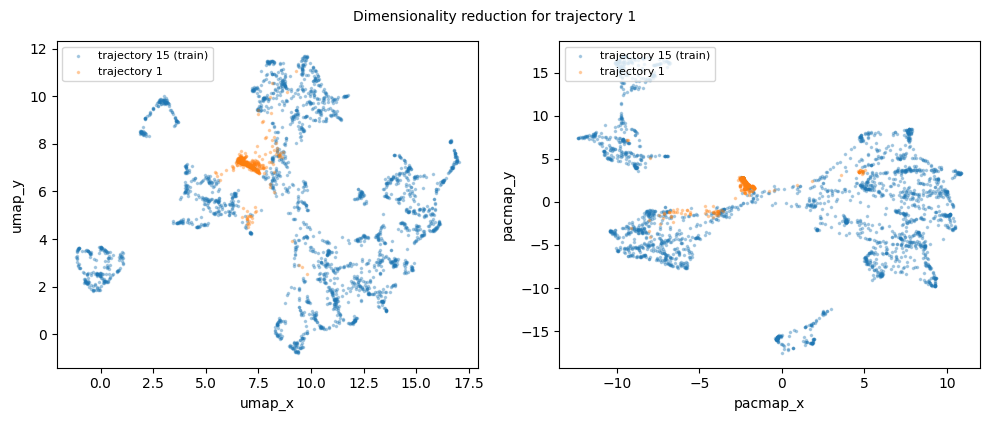

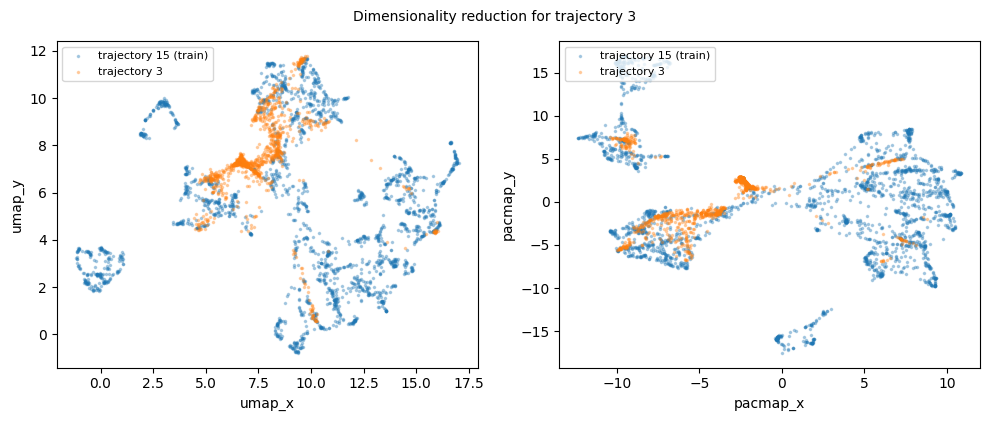

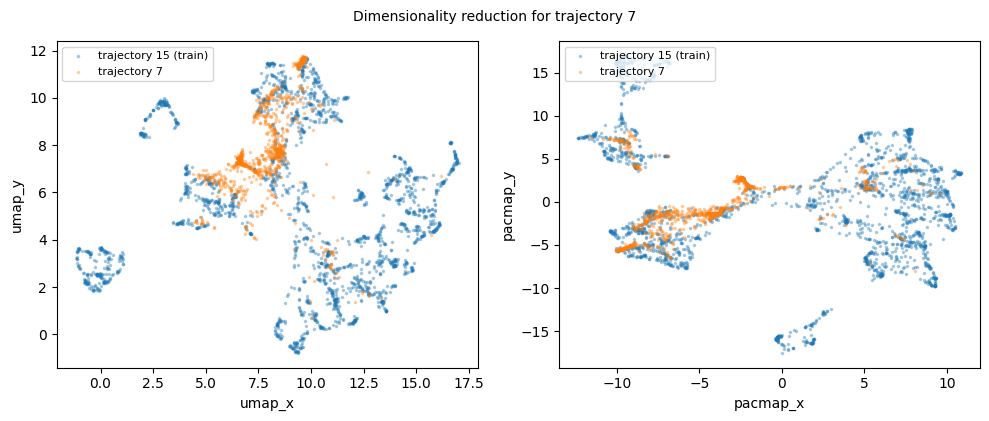

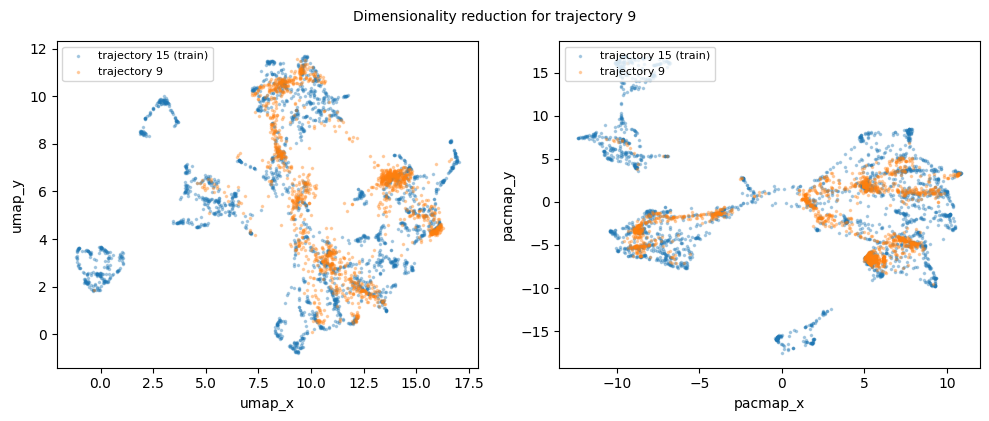

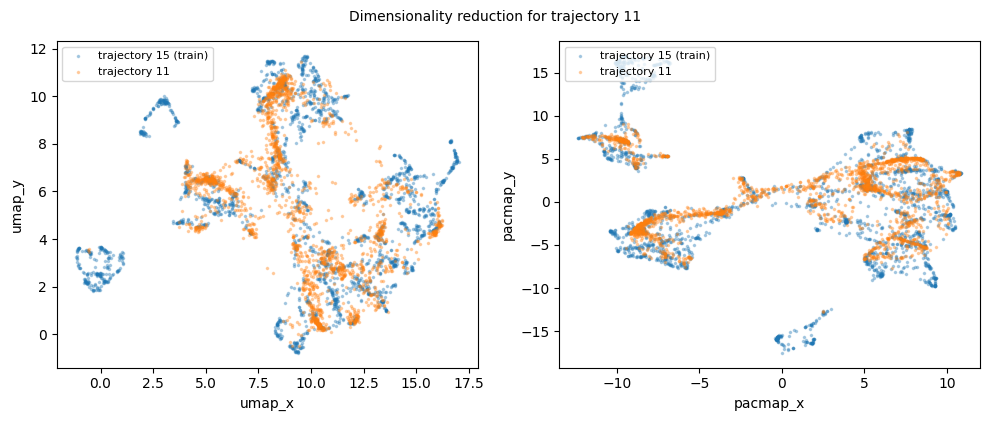

...

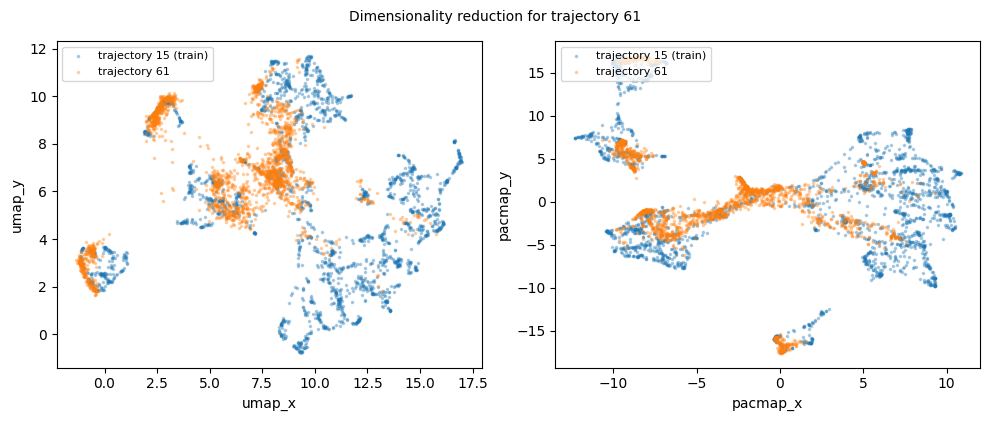

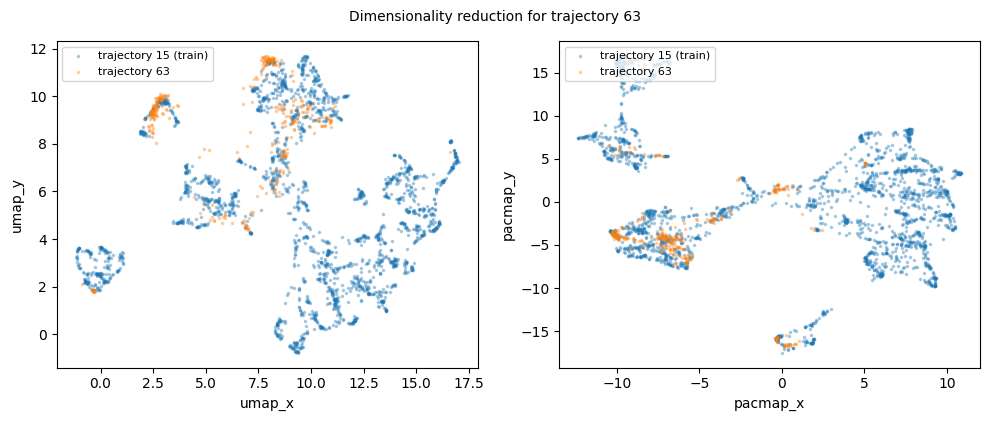

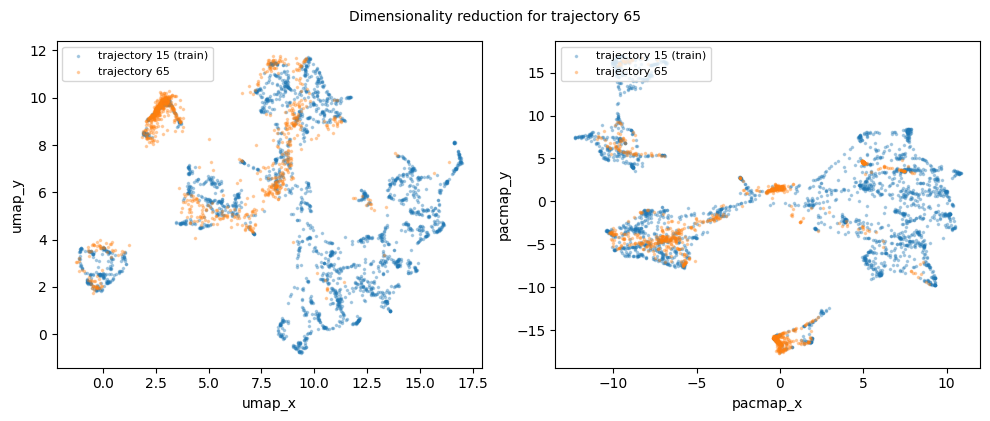

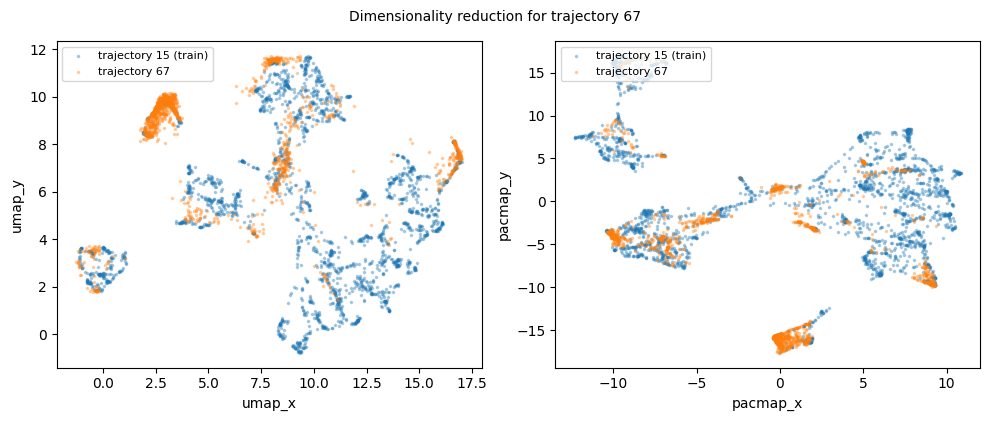

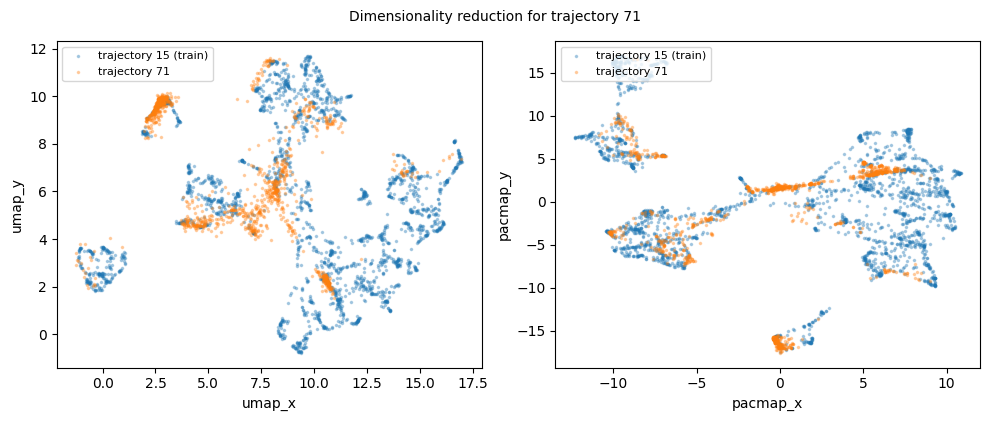

In [10]:
Clusters.plotEmbedding(nfigures=24)

### Comparison of clusters by dimensionality reduction algorithm

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:146: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



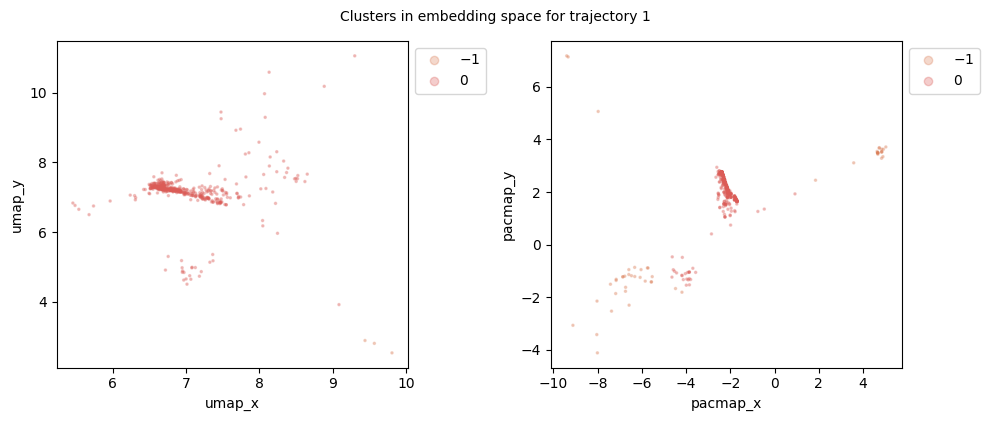

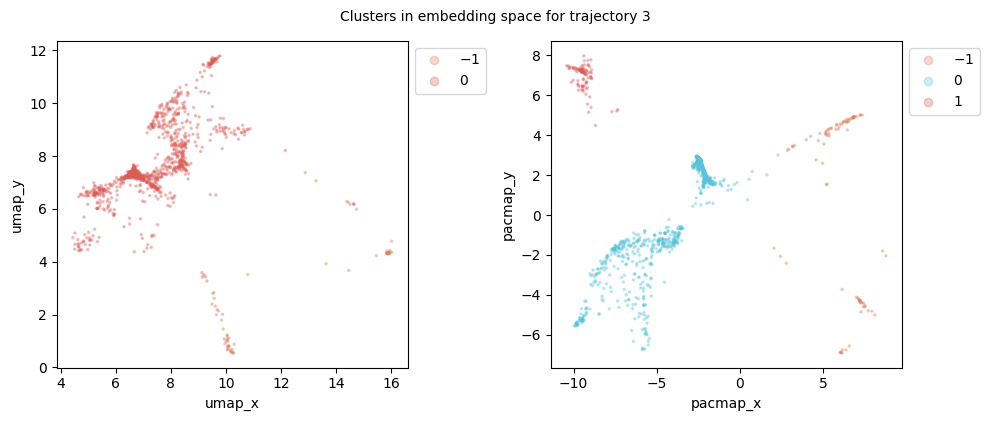

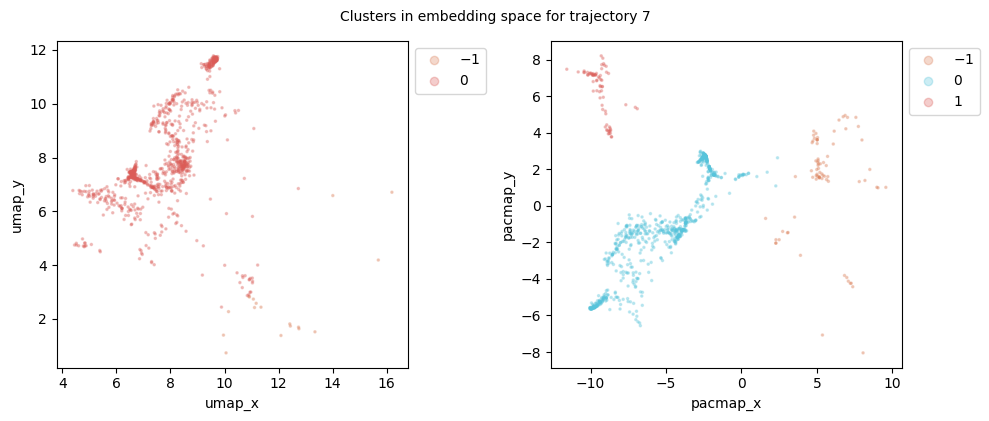

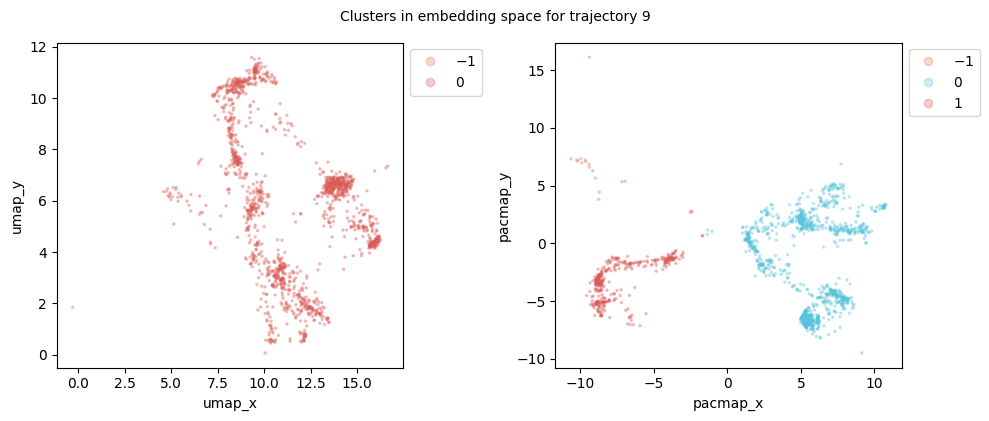

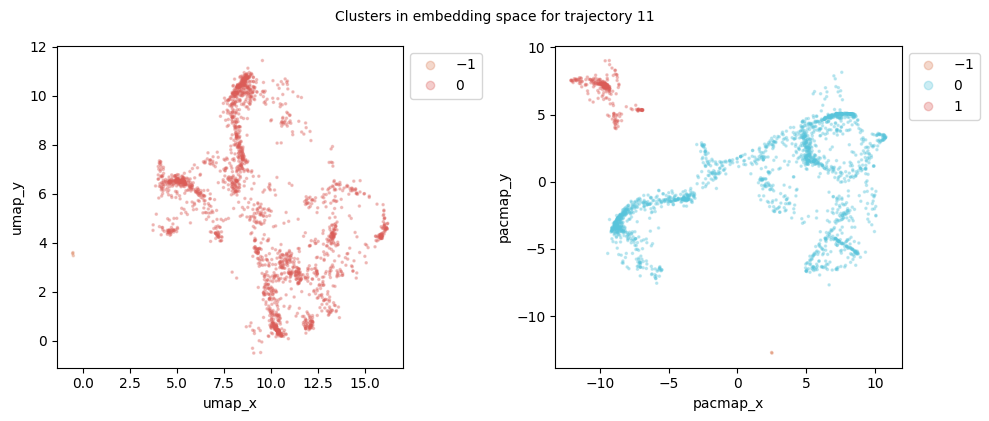

...

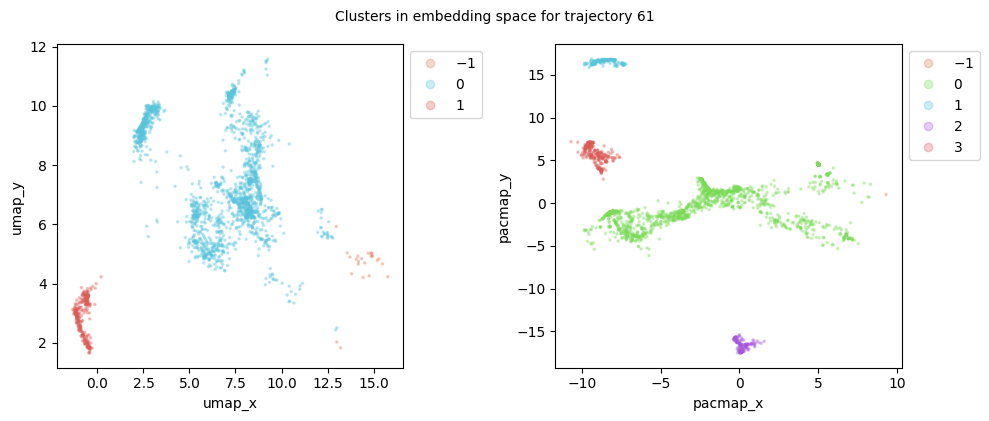

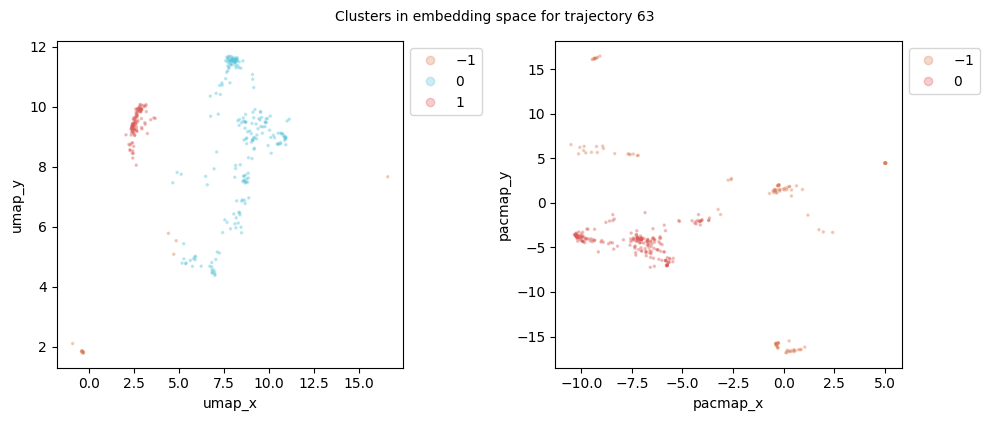

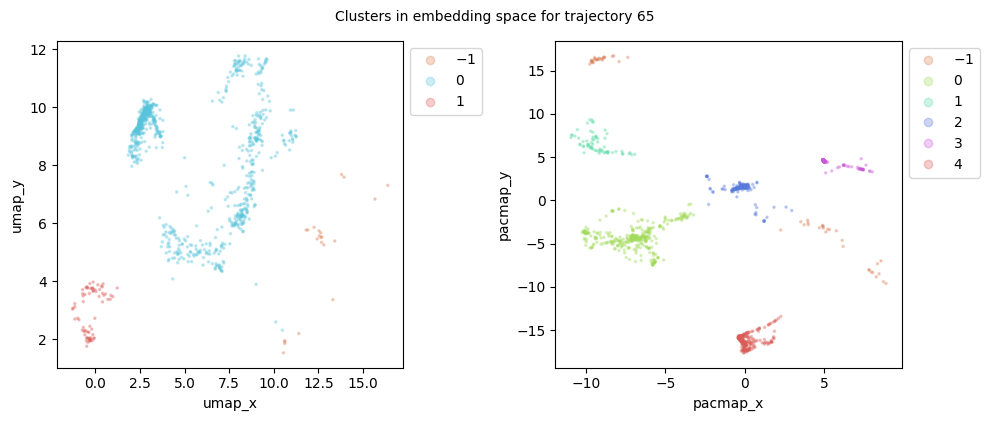

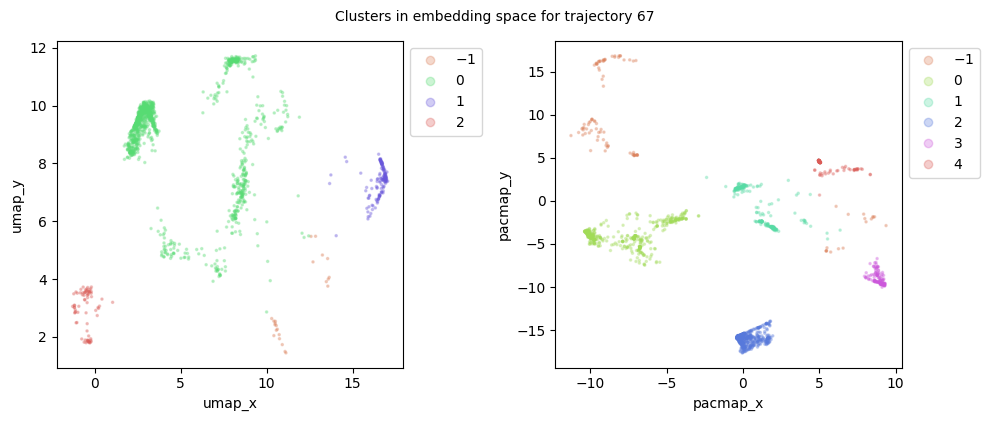

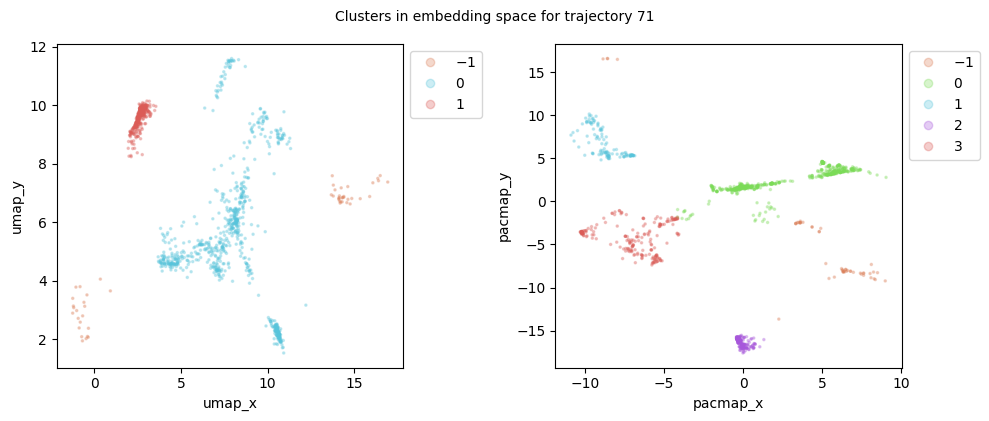

In [11]:
Clusters.plotResults(nfigures=24)

### Clusters in embedding space

In [12]:
# Clusters.plotFigure('scatter2D', 
#                     idxTrajectory   = 5, 
#                     idxVariable     = 10, 
#                     algorithm       = 'pacmap')

### Time series colored by clusters

In [13]:
def plotFigure(typePlot, idxTrajectory, idxVariable, algorithm):
        data       = Clusters.getTrajectory(idxTrajectory)
        variable   = data.select_dtypes('number').columns[idxVariable]
        data[f'real_cluster_{algorithm}']=data[f'real_cluster_{algorithm}'].astype('str')

        if typePlot  == 'lineplot':
            lineAndScatterPlot(data, 
                               x     = 'tiempo', 
                               y     = variable, 
                               color = f'real_cluster_{algorithm}',
                               title = f'Clusters from trajectory {Clusters.trajectory}')
        

In [14]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory   = 20, 
                    idxVariable     = 0, 
                    algorithm       = 'pacmap')

# Clusters Comparison

In [15]:
# dfSimilarClusters = Clusters.getSimilarClusters(algorithm = 'pacmap', 
#                                                 threshold = 5)

In [16]:
# idxGroupCluster = 10
# scatterPlot2D(data  = dfSimilarClusters[dfSimilarClusters['group']==idxGroupCluster], 
#               x     = 'pacmap_x', 
#               y     = 'pacmap_y',
#               #z     = 'pacmap_z', 
#               color = 'label',
#               title = 'Similar clusters')

## Unified Clusters

In [17]:
Clusters.getSimilarClusters(algorithm = 'umap', threshold = 5)
Clusters.unifyClusters(algorithm='umap')

Clusters.getSimilarClusters(algorithm = 'pacmap', threshold = 5)
Clusters.unifyClusters(algorithm='pacmap')

In [19]:
import matplotlib.pyplot as plt

def plotVarByCluster(idxTrajectory, variable, algorithm):
    dataTrajectory = Clusters.getTrajectory(idxTrajectory).copy()
    clusterLabels  = dataTrajectory[f'real_cluster_{algorithm}'].astype('int').unique()
    clusterLabels = np.sort(clusterLabels).astype('int')
    #clusterLabels  = clusterLabels[clusterLabels!=-1]

    ymax           = dataTrajectory[dataTrajectory[f'real_cluster_{algorithm}'].isin(clusterLabels)][variable].max()
    ymin           = dataTrajectory[dataTrajectory[f'real_cluster_{algorithm}'].isin(clusterLabels)][variable].min()
    ncols          = len(clusterLabels)

    fig, axes      = plt.subplots(nrows   = 1, 
                                  ncols   = ncols, 
                                  figsize = (2*ncols, 4))
    for j, cluster in enumerate(clusterLabels):
        dataFiltered = dataTrajectory[dataTrajectory[f'real_cluster_{algorithm}']==cluster]
        axes[j].scatter(x = dataFiltered.reset_index().index, 
                        y = dataFiltered[variable], 
                        s = 5)
        
        #axes[j].set_ylim(ymin, ymax)
        axes[j].set_title(f'Cluster {cluster}', 
                            fontsize = 8)

        if j==0:
            axes[j].set_ylabel(f'{variable}')
        else:
            axes[j].yaxis.set_visible(False)

    fig.tight_layout()
    fig.suptitle(f'Comparison of the {variable} by clusters for trajectory {Clusters.trajectory}', 
                    fontsize = 15, 
                    y        = 1.04)
    plt.show()

In [ ]:
d=Clusters.getTrajectory(5)
d['real_cluster_pacmap']=d['real_cluster_pacmap'].astype('str')
scatterPlot2D(data  = d, 
              x     = 'pacmap_x', 
              y     = 'pacmap_y',
              color = 'real_cluster_pacmap',
              title = f'Clusters for trajecotry {Clusters.trajectory}')

In [97]:
#Clusters.
plotFigure('lineplot', 
                    idxTrajectory   = 21, 
                    idxVariable     = 3, 
                    algorithm       = 'pacmap')

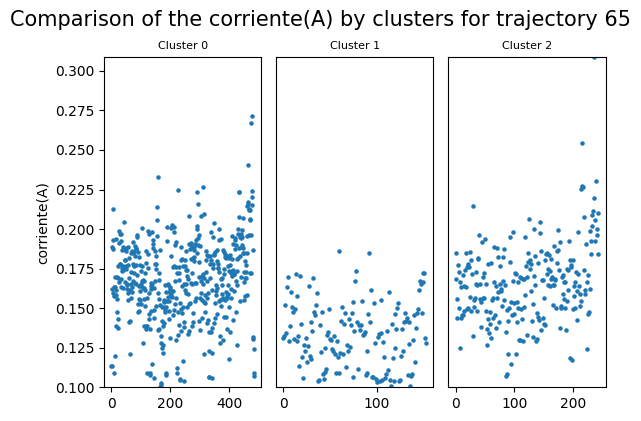

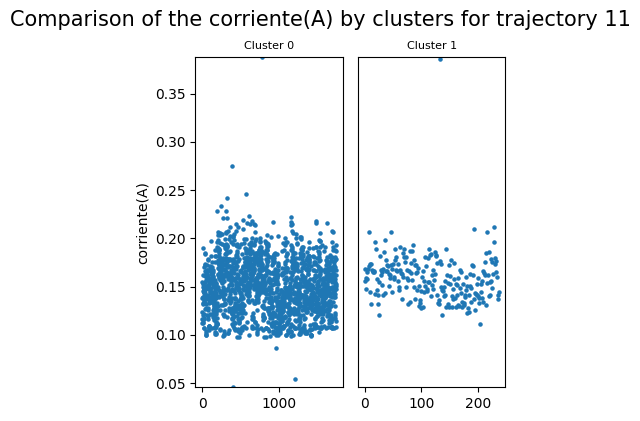

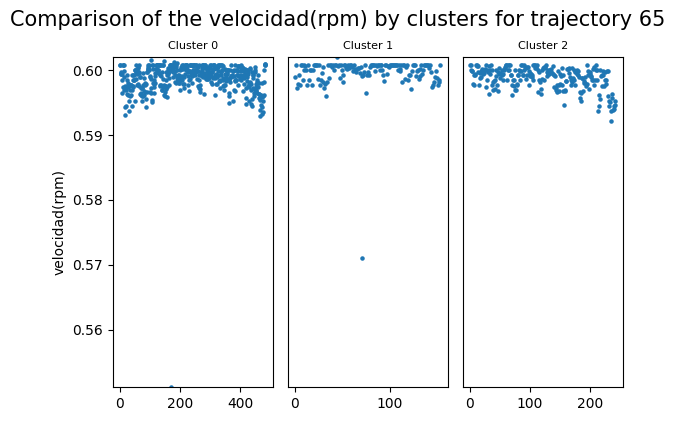

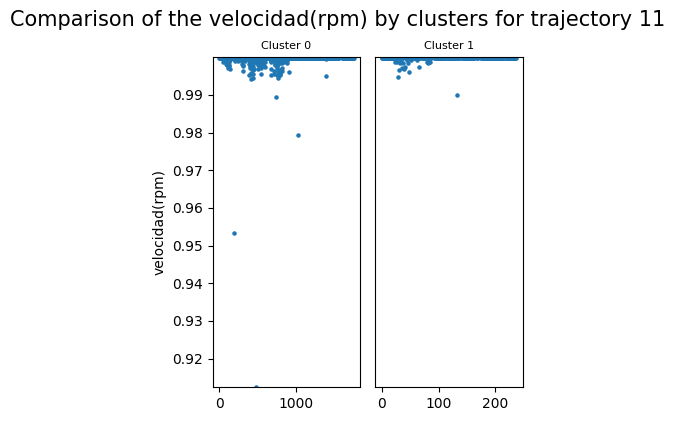

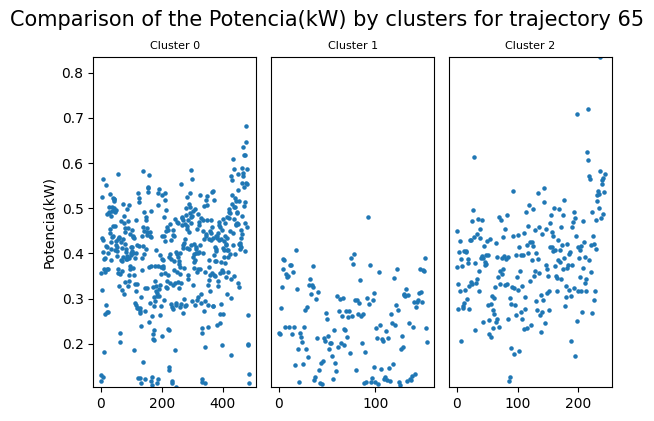

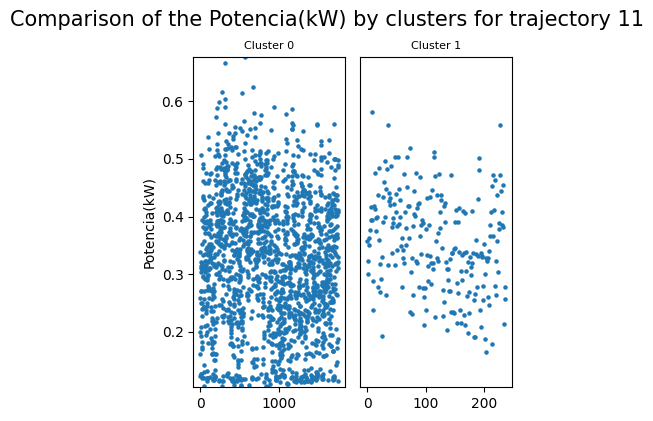

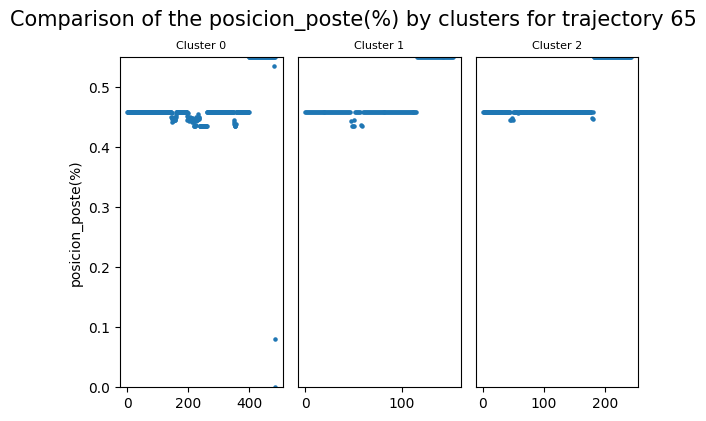

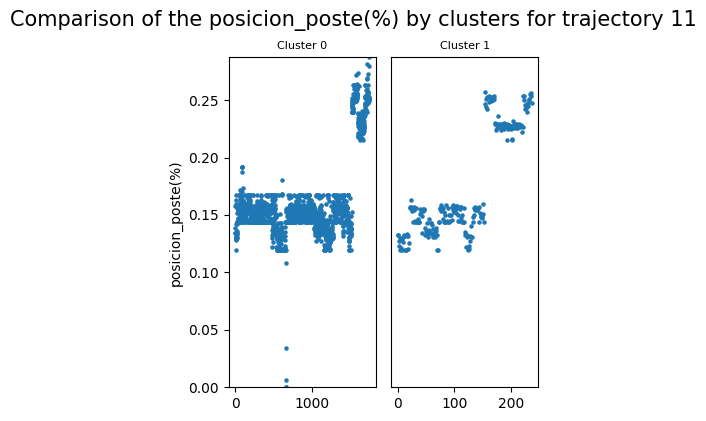

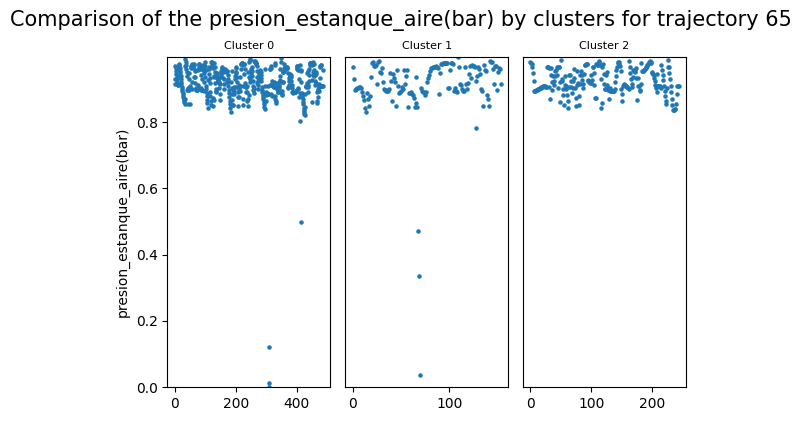

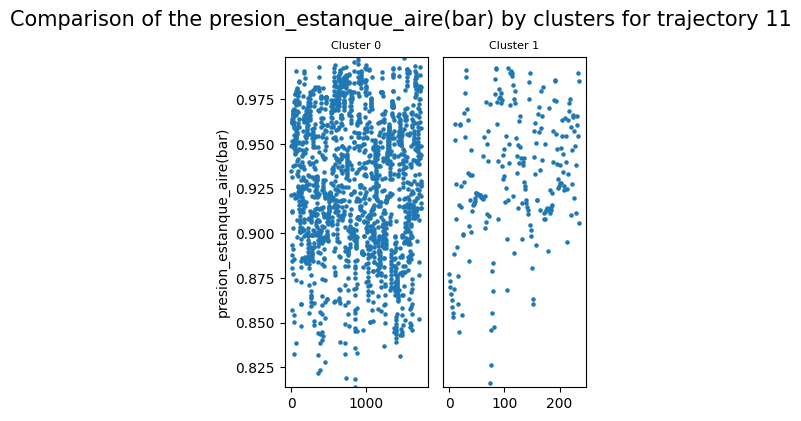

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.



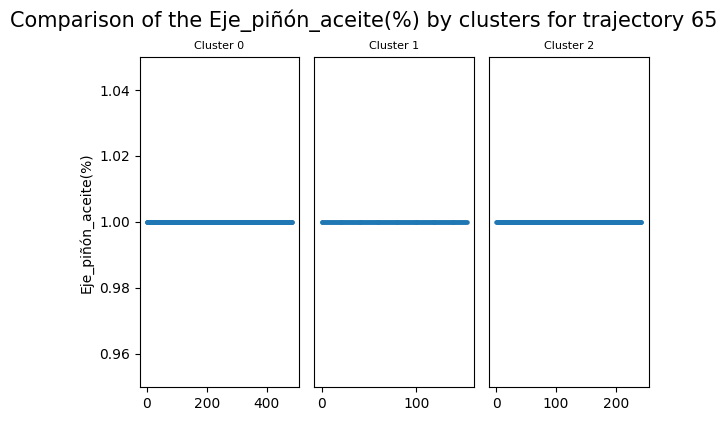

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.



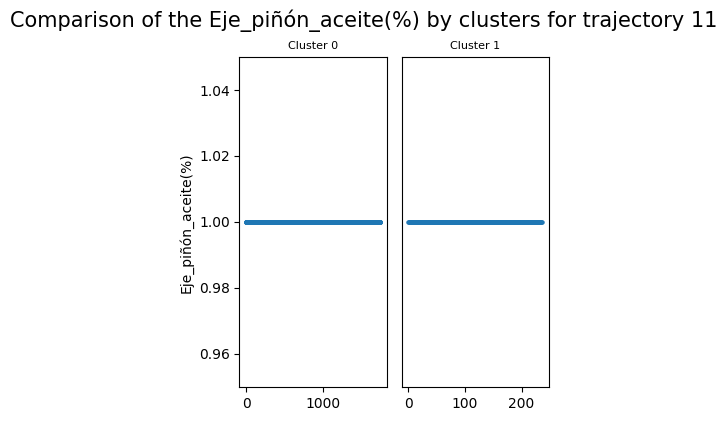

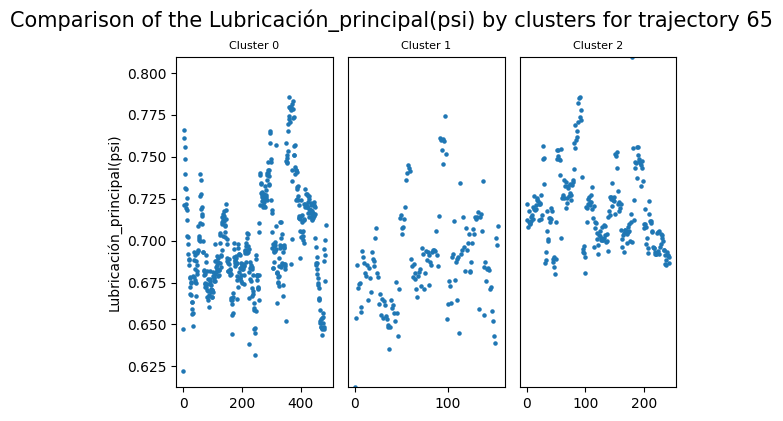

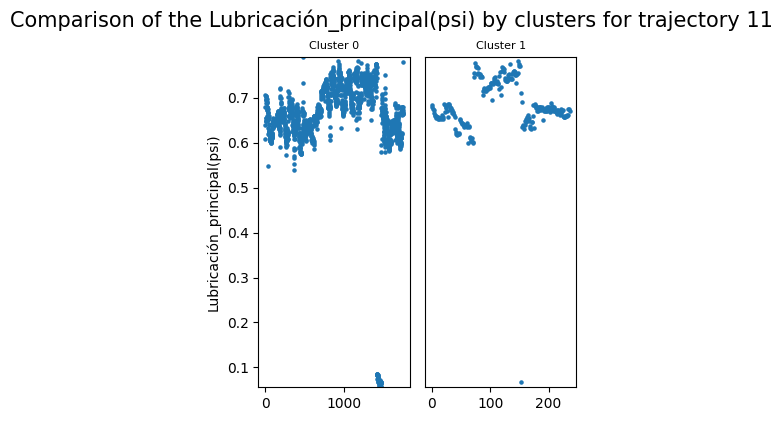

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\clustering\plotClustering.py:236: UserWarning:

Attempting to set identical low and high ylims makes transformation singular; automatically expanding.



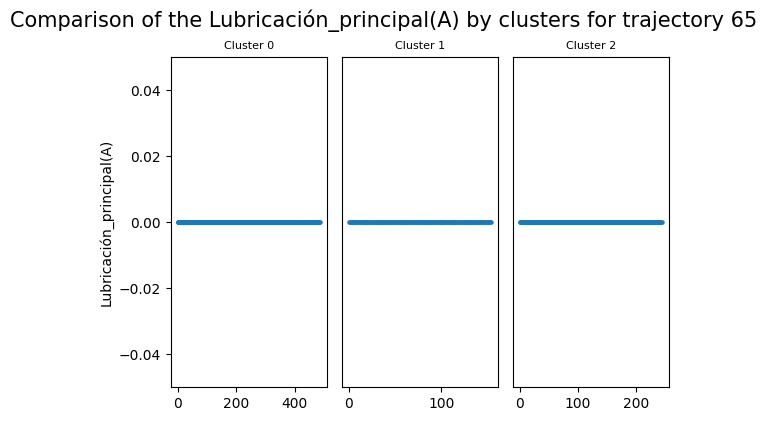

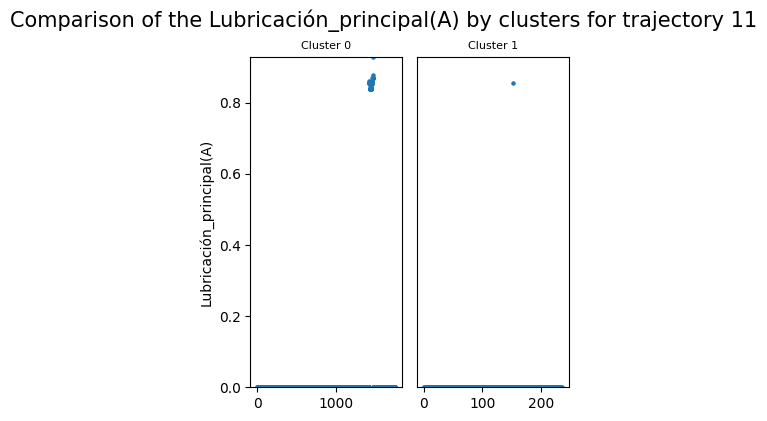

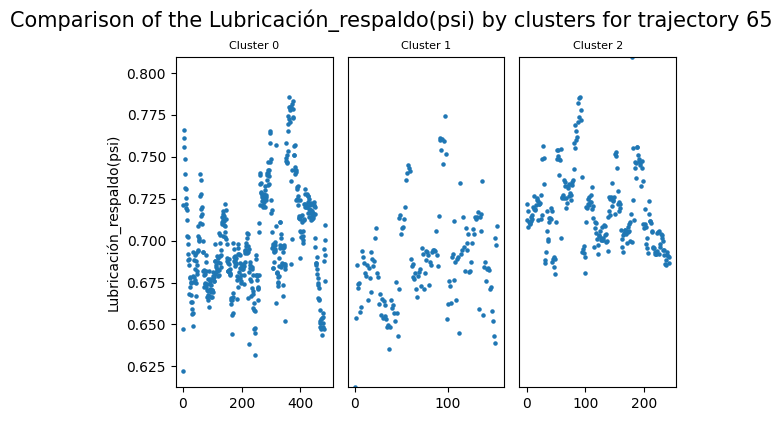

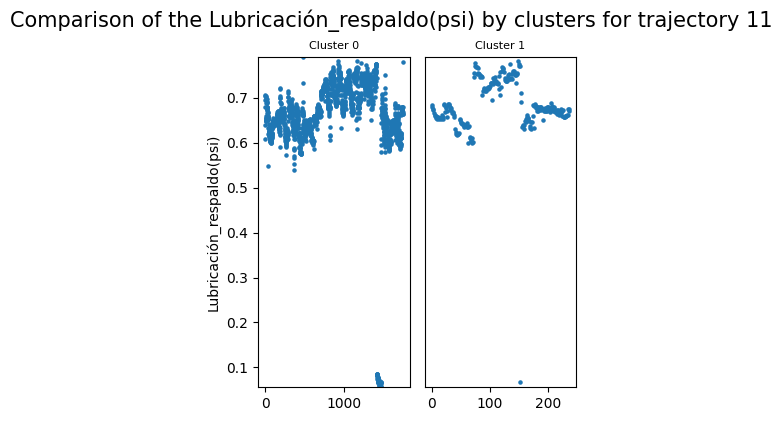

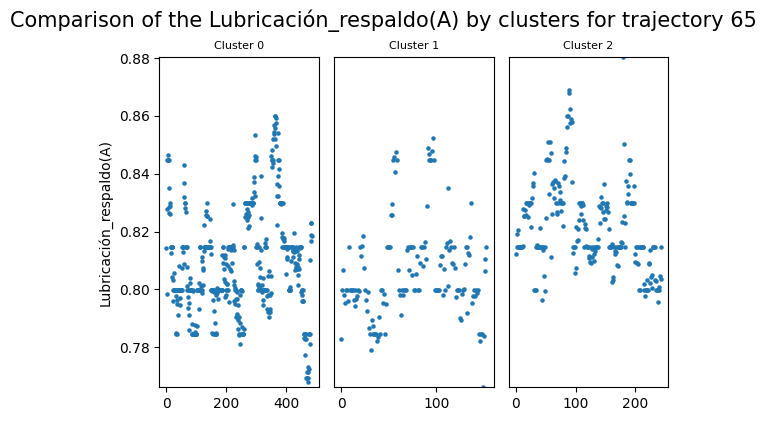

...

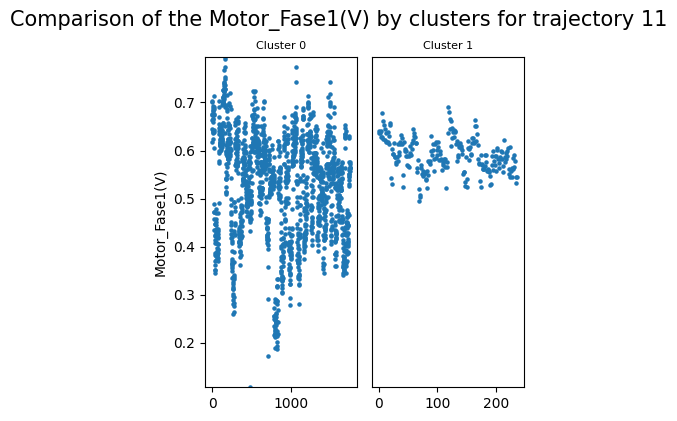

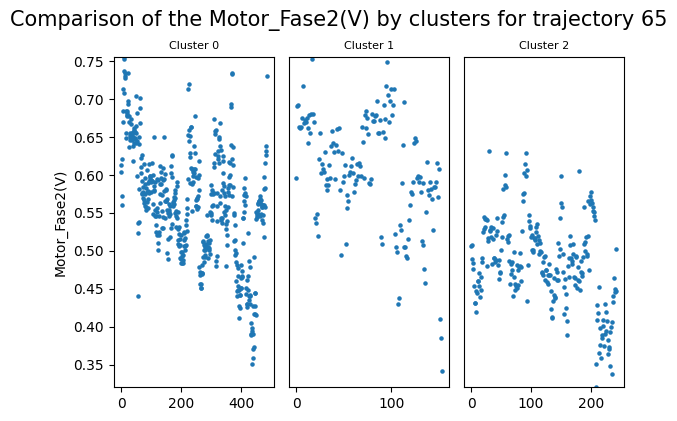

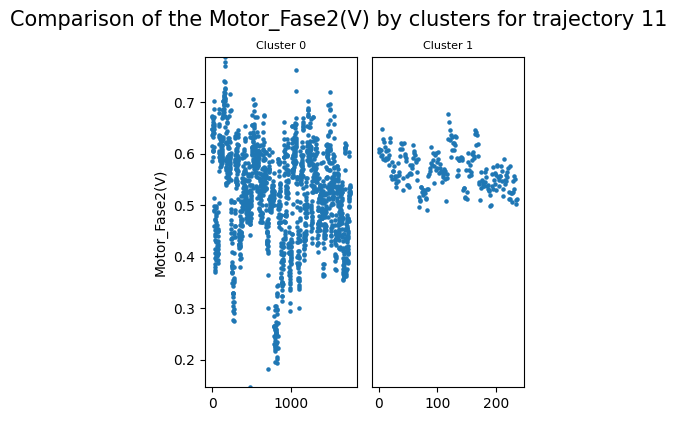

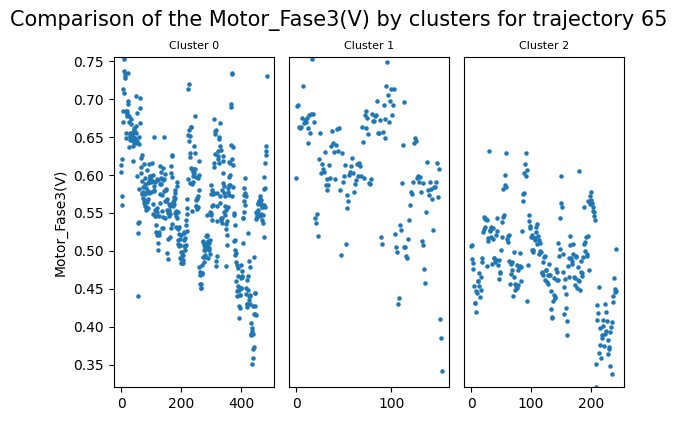

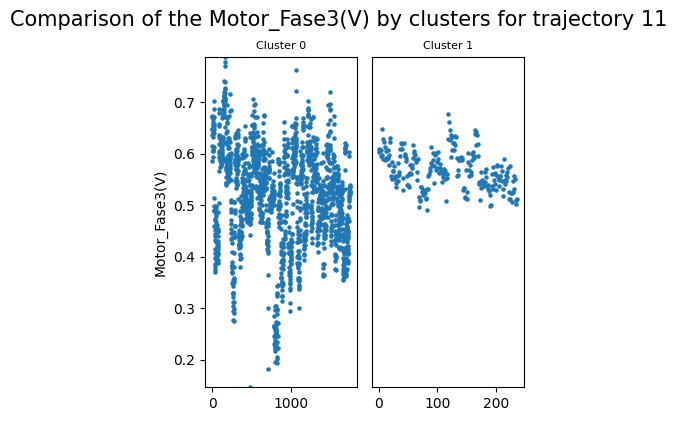

In [23]:
#variable = dfManipulableVar.columns[0]
for variable in dfManipulableVar.columns:
    Clusters.plotVarByCluster(idxTrajectory = 21, 
                            variable      = variable, 
                            algorithm     = 'pacmap')
                            
    Clusters.plotVarByCluster(idxTrajectory = 4, 
                            variable      = variable, 
                            algorithm     = 'pacmap')

In [45]:
def applyLabel(cluster):
    if cluster==0:
        return 'normal operation'
    elif cluster==1:
        return 'normal operation type B'
    elif cluster==2:
        return 'small decreasing oscillations in lubrication'
    else:
        'outlier'

In [87]:
dataResults=pd.concat(list(Clusters.clustersResults.values()))

In [88]:
dataResults['label'] = dataResults['real_cluster_pacmap'].apply(lambda row: applyLabel(row))
#dataResults['label'] = dataResults['real_cluster_pacmap'].apply(lambda row: chr(ord('A') + int(row)))
#dataResults['label'].replace('@', 'Z', inplace=True)

In [53]:
from transformers import GPT2Tokenizer, GPT2LMHeadModel, Trainer, TrainingArguments
import torch

In [54]:
def predict_next_words(sequence, model, tokenizer, num_words):
    # tokenization
    input_ids = tokenizer.encode(sequence, return_tensors='pt')

    # generate next words
    with torch.no_grad():
        output = model.generate(
            input_ids=input_ids,
            max_length=len(input_ids[0]) + num_words, 
            pad_token_id=model.config.eos_token_id,
            #num_return_sequences=1,
            do_sample=True,
            top_k=50,
            top_p=0.95,
        )
    
    # decode words
    next_words = tokenizer.decode(output[0, len(input_ids[0]):], skip_special_tokens=True)
    
    return next_words

In [89]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")

In [92]:
i=5700
sequence = ' '.join(dataResults['label'].iloc[i:i+36]) 
num_words = 6  # number of words to predict

next_words = predict_next_words(sequence, model, tokenizer, num_words)
print('input:', sequence)
print('prediction:',next_words)


input: normal operation normal operation normal operation normal operation normal operation normal operation type B normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation normal operation
prediction:  normal operation normal operation normal operation


# -----------------------

### Relationship between clusters of trajectories

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
import plotly.graph_objs as go

In [ ]:
def plotGraph():
    # Assign colors to nodes based on the connected component they belong to
    colors     = ['red', 'royalblue', 'green', 'orange', 'purple', 'yellow'] # Change length of colors
    nodeColors = {}
    edgeColors = {}

    for i, component in enumerate(Clusters.connectedComponents):

        # Add colors to node and edges
        for node in component:
            nodeColors[node] = colors[i % len(colors)]

        for edge in Clusters.Graph.edges():
                if edge[0] in component and edge[1] in component:
                    edgeColors[edge] = colors[i % len(colors)]

    # Add position to graph        
    pos = {}
    for node in Clusters.Graph.nodes():
        pos[node] = (node[0], node[1])

    # Create figure
    plt.figure(figsize  = (8, 6))
    nx.draw(G           = Clusters.Graph, 
            pos         = pos, 
            with_labels = True, 
            node_size   = 400, 
            font_size   = 6, 
            arrowsize   = 10,
            node_color  = [nodeColors[node] for node in Clusters.Graph.nodes()],  
            edge_color  = [edgeColors[edge] for edge in Clusters.Graph.edges()], 
            )

    plt.xlabel('trajectories')
    plt.ylabel('clusters')
    plt.title("Assignment found between similar clusters")
    plt.show()

In [ ]:
def plotGraph():
    colors = px.colors.qualitative.Plotly 

    # Add position to graph
    pos = {}
    for node in Clusters.Graph.nodes():
        pos[node] = (node[0], node[1])
        
    fig = go.Figure()

    # Create empty lists to store legend data
    legend_items = []

    # Add components to the figure
    for i, component in enumerate(Clusters.connectedComponents):
        node_trace = []
        edge_trace = []

        # Add colors to nodes and edges
        node_color = colors[i % len(colors)]
        # Add legend item for each component
        if i not in legend_items:
            node_trace.append(go.Scattergl(x=[None], y=[None],
                                        mode='markers',
                                        marker=dict(size=10, color=node_color),
                                        name=f'Component {i}',
                                        legendgroup='group'+str(i),
                                        showlegend=True))
            legend_items.append(i)

        for node in component:
            node_trace.append(go.Scattergl(x=[pos[node][0]], y=[pos[node][1]],
                                        mode='markers',
                                        marker=dict(size=15, color=node_color),
                                        text=str(node),
                                        hoverinfo='text',
                                        legendgroup='group'+str(i),
                                        showlegend=False))

        for edge in Clusters.Graph.edges():
            if edge[0] in component and edge[1] in component:
                edge_trace.append(go.Scattergl(x=[pos[edge[0]][0], pos[edge[1]][0]],
                                            y=[pos[edge[0]][1], pos[edge[1]][1]],
                                            mode='lines',
                                            line=dict(color=node_color, width=2),
                                            hoverinfo='none',
                                            legendgroup='group'+str(i),
                                            showlegend=False))

        fig.add_traces(node_trace + edge_trace)

    #for node, (x, y) in pos.items():
     #   fig.add_annotation(x=x, y=y, text=str(node), showarrow=False, font=dict(color="black", size=5))

    fig.update_layout(title="Assignment found between similar clusters",
                    xaxis_title="trajectories",
                    yaxis_title="clusters",
                    showlegend=True,
                    width=900,
                    height=700)
    fig.show()

In [ ]:
plotGraph()

In [ ]:
Clusters.plotGraph()

## Graph the final clusters

In [ ]:
Clusters.plotResults(nfigures=2, 
                     label_color='real_cluster')

In [ ]:
for variable in dfManipulableVar.columns[16:17]:
    Clusters.plotVarByCluster(idxTrajectory = 5, 
                          variable      = variable, 
                          algorithm     = 'pacmap')